# Willett 2023 (neural to characters, CTC)

Decodes the **50 Hz neural features of area 6v** (threshold crossings + spike-band power) into the **character sequence** of the sentence the participant attempted to speak, with a CTC loss. The target is characters rather than phonemes because the `sentences` release ships no phoneme labels (the authors' labels live in `derived/tfRecords`, out of scope), so it comes straight from `Sentence.text` through the frozen `CharacterEncoder` charset. The metric is the character error rate (CER).

The recipe follows the paper where a small model can: **area 6v only** (the paper decoded from the 128 area 6v channels), the **published competition partition** (`original_split`, each day's train blocks against its test block), **per-block normalization** and a **length-aware model**. Two consecutive vocal sessions, 06.16 and 06.21. The Study query also keeps `valid` timelines only, the habit every model should have.

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

import neuralset as ns
from neuralshed import transforms
from neuralshed.text import CharVocab, normalize_text, ctc_min_input_length
from neuralshed.extractors import NeuralFeatureExtractor, CharacterEncoder
from neuralshed.dataloader import RaggedSegmenter, RaggedCollator, PadSpec
from neuralshed.datasets.willet_2023 import study
from neuralshed.datasets.utils import dataset_dir

pd.set_option("display.max_columns", None)
torch.manual_seed(0)

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("willet_2023") / "data"
s = study.Willett2023Sentences(path=root)
s.download()

FS = 50.0
SESSIONS = ["t12.2022.06.16", "t12.2022.06.21"]   # two consecutive vocal days, 40-trial blocks, all valid
VOCAB = CharVocab.canonical()                      # 29 classes: blank + space + apostrophe + a-z
print(VOCAB)

# rows of the (512, T) input that belong to area 6v: the extractor concatenates SpikeCounts
# (rows 0-255) then BandPower (rows 256-511), and each stream is in array order, 6v first
AREA_6V = torch.cat([torch.arange(0, 128), torch.arange(256, 384)])


def conv_len(n):
    """Output length of one conv with kernel 5, stride 2, padding 2."""
    return (n + 2 * 2 - 5) // 2 + 1


def frame_mask(lengths, n_frames):
    """(B, 1, n_frames) mask that is 1 on each trial's valid frames."""
    return (torch.arange(n_frames)[None, :] < lengths[:, None]).unsqueeze(1).to(torch.float32)


def levenshtein(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev = d[0]
        d[0] = i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[-1]


def greedy(logp, n):
    """(T', C) log-probs over n valid frames -> collapsed character ids."""
    out = []
    prev = -1
    for v in logp[:n].argmax(-1).tolist():
        if v != prev and v != VOCAB.BLANK:
            out.append(v)
        prev = v
    return out

2026-10-15 12:09:57 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/willet_2023/data/Willett2023Sentences.


2026-10-15 12:09:57 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/willet_2023/data/Willett2023Sentences (skipped 0 non-owned items).


CharVocab(version='v1', n_classes=29)


## 1. Two sessions, the published split

`AssignSourceSplit` maps the competition partition onto the `split` column: `train` and `test` keep their names, and the blocks outside the partition (the 50-sentence set and the repeated Switchboard blocks) become `""`, which this notebook drops.

In [2]:
chain = ns.Chain(steps={
    "study": study.Willett2023Sentences(path=root, query=f"session in {SESSIONS} and valid"),
    "split": transforms.AssignSourceSplit(mapping={"train": "train", "test": "test"}),
})
events = chain.run()

sentences = events[events.type == "Sentence"]
print("timelines:", events.timeline.nunique(), "| trials:", len(sentences))
display(pd.crosstab(sentences.session, sentences.split.replace("", "(unassigned)"), margins=True))

# blocks per session and split, all of them valid
blocks = sentences.drop_duplicates("timeline")
assert blocks.valid.all()
display(pd.crosstab(blocks.session, blocks.split.replace("", "(unassigned)")))

# every block belongs to exactly one split
per_block = sentences.groupby(["session", "block"]).split.nunique()
print("blocks with more than one split:", int((per_block > 1).sum()))

# prompts shared between the two splits of these days
train_texts = set(sentences[sentences.split == "train"].text.map(normalize_text))
test_texts = sentences[sentences.split == "test"].text.map(normalize_text)
print("test trials whose sentence also occurs in train:", int(test_texts.isin(train_texts).sum()), "of", len(test_texts))

timelines: 21 | trials: 860


split,(unassigned),test,train,All
session,,,,
t12.2022.06.16,90,40,320,450
t12.2022.06.21,50,40,320,410
All,140,80,640,860


split,(unassigned),test,train
session,,,
t12.2022.06.16,2,1,8
t12.2022.06.21,1,1,8


blocks with more than one split: 0
test trials whose sentence also occurs in train: 0 of 80


## 2. One segment per trial

- `neural`: the two streams concatenated to `(512, T)` at 50 Hz in native units (counts per bin and µV²). The per-block z-score of the next section removes the units, so no rate conversion is requested. The area 6v rows (`AREA_6V`) are selected when the batch is normalized, so the model input is `(256, T)`.
- `target`: the character ids of the `Sentence` text through the frozen 29-class vocabulary.

A CTC target needs at least `len(ids) + adjacent repeats` emission frames. The model emits at 25 Hz (one stride-2 conv), which keeps short sentences decodable: a 5 s attempt gives 125 frames for a sentence of up to about 90 characters. Trials shorter than their target after the conv are dropped and reported, as are the trials outside the partition.

In [3]:
CACHE = dict(folder=dataset_dir("willet_2023") / "cache", keep_in_ram=False)   # extractor disk cache

segmenter = RaggedSegmenter(
    extractors={
        "neural": NeuralFeatureExtractor(target_unit="native", frequency=FS, aggregation="cat", infra=CACHE),
        "target": CharacterEncoder(aggregation="trigger"),
    },
    trigger_query="type == 'Sentence'",
    duration=None,                                   # each segment inherits its sentence duration
    metadata_columns=("split", "text", "timeline", "session", "block", "valid"),
)
dataset = segmenter.apply(events)
dataset.prepare()

sample = dataset[0]
print("neural:", tuple(sample.data["neural"].shape), "| target:", tuple(sample.data["target"].shape))
print("text  :", repr(sample.metadata["text"]))
print("ids   :", repr(VOCAB.decode(sample.data["target"].tolist())))

keep = []
dropped = []
for i in range(len(dataset)):
    item = dataset[i]
    in_partition = item.metadata["split"] in ("train", "test")
    frames = conv_len(item.data["neural"].shape[-1])
    need = ctc_min_input_length(item.data["target"].tolist())
    keep.append(in_partition and frames >= need)
    if in_partition and frames < need:
        dropped.append((item.metadata["text"], frames, need))
dataset = dataset.select(np.array(keep))
print(dataset)
print(f"dropped {len(dropped)} partition trials whose emission frames cannot hold the target:")
for text, frames, need in dropped:
    print(f"  {frames} frames < {need} needed: {text!r}")

2026-10-15 12:09:59 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


  0%|          | 0/42 [00:00<?, ?it/s]

  2%|▏         | 1/42 [00:02<01:48,  2.64s/it]

  5%|▍         | 2/42 [00:04<01:24,  2.12s/it]

 10%|▉         | 4/42 [00:06<00:51,  1.37s/it]

...

 98%|█████████▊| 41/42 [00:23<00:00,  2.35it/s]

100%|██████████| 42/42 [00:23<00:00,  1.77it/s]

2026-10-15 12:10:39 - INFO - neuralset.dataloader:222 - Preparing extractor: CharacterEncoder


neural: (512, 252) | target: (29,)
text  : "I'm sure you'd find something."
ids   : "i'm sure you'd find something"


RaggedSegmentDataset(720 segments, extractors: neural, target, metadata: split, text, timeline, session, block, valid)
dropped 0 partition trials whose emission frames cannot hold the target:


## 3. Per-block normalization

The features are refit at the start of every session and drift within it, so the authors z-score every block with its own statistics (online, a rolling estimate over the block's most recent sentences). Here each block's per-channel mean and standard deviation are computed over the go-period frames of its own trials. That uses the block's neural data and no labels, so the test block is normalized by itself exactly as the online system would have. The statistics are computed on the area 6v rows only, which is all the model sees.

In [4]:
train_ds = dataset.select(dataset.metadata.split.eq("train").to_numpy())
test_ds = dataset.select(dataset.metadata.split.eq("test").to_numpy())
print(f"train trials: {len(train_ds)} | test trials: {len(test_ds)}")

collate = RaggedCollator(
    fields={
        "neural": PadSpec(axis=-1, pad_value=0),
        "target": PadSpec(axis=0, pad_value=0),
    }
)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, collate_fn=collate)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, collate_fn=collate)

# per-block statistics over the valid go-period frames of the area 6v rows
n_in = len(AREA_6V)
total = {}
total_sq = {}
n_frames = {}
for b in DataLoader(dataset, batch_size=32, shuffle=False, collate_fn=collate):
    mask = b.valid_mask("neural").unsqueeze(1)                       # (B, 1, T)
    x = b.data["neural"][:, AREA_6V] * mask                          # (B, 256, T)
    for k, timeline in enumerate(b.metadata["timeline"]):
        total[timeline] = total.get(timeline, torch.zeros(n_in)) + x[k].sum(-1)
        total_sq[timeline] = total_sq.get(timeline, torch.zeros(n_in)) + (x[k] ** 2).sum(-1)
        n_frames[timeline] = n_frames.get(timeline, 0) + int(mask[k].sum())

block_mu = {}
block_sd = {}
for timeline in total:
    mu = total[timeline] / n_frames[timeline]
    block_mu[timeline] = mu
    block_sd[timeline] = (total_sq[timeline] / n_frames[timeline] - mu ** 2).clamp_min(0).sqrt() + 1e-6
print(f"{len(block_mu)} blocks, {min(n_frames.values())}-{max(n_frames.values())} frames per block")


def normalized(batch):
    """(B, 256, T) area 6v input with its block's statistics removed, padded frames kept at zero."""
    mu = torch.stack([block_mu[t] for t in batch.metadata["timeline"]]).unsqueeze(-1)
    sd = torch.stack([block_sd[t] for t in batch.metadata["timeline"]]).unsqueeze(-1)
    x = (batch.data["neural"][:, AREA_6V] - mu) / sd
    return x * batch.valid_mask("neural").unsqueeze(1)

train trials: 640 | test trials: 80


18 blocks, 10394-14401 frames per block


## 4. A compact CTC decoder

One strided temporal conv (50 Hz to 25 Hz) + a 2-layer bidirectional GRU + a per-frame linear head over the **29 classes** (blank + 28 characters), read as CTC emissions. The GRU runs on packed sequences, so a trial's emissions do not depend on how much padding its batch carries.

In [5]:
class CTCDecoder(nn.Module):
    def __init__(self, c_in=256, n_classes=VOCAB.n_classes, hidden=128, p=0.2):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(c_in, 256, 5, 2, 2), nn.ReLU(), nn.Dropout(p))
        self.gru = nn.GRU(256, hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=p)
        self.head = nn.Linear(2 * hidden, n_classes)

    def forward(self, x, lengths):                   # x: (B, 256, T), lengths: (B,) valid bins
        h = self.conv(x)
        n_valid = conv_len(lengths)
        # zero the frames past each trial's valid length, so the GRU packs only real frames
        h = h * frame_mask(n_valid, h.shape[-1])
        packed = pack_padded_sequence(h.transpose(1, 2), n_valid.cpu(), batch_first=True, enforce_sorted=False)
        packed, _ = self.gru(packed)
        h, _ = pad_packed_sequence(packed, batch_first=True, total_length=h.shape[-1])
        return self.head(h).log_softmax(-1), n_valid  # (B, T', 29), valid emission frames


model = CTCDecoder()
print(model)
print(sum(p.numel() for p in model.parameters()), "parameters")

CTCDecoder(
  (conv): Sequential(
    (0): Conv1d(256, 256, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (gru): GRU(256, 128, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (head): Linear(in_features=256, out_features=29, bias=True)
)
928285 parameters


## 5. Train (CTC loss) and track the character error rate

CTC sits on an all-blank plateau for the first epochs. A one-cycle schedule keeps the learning rate high through the escape. The test CER is printed along the way for information only, nothing is selected on it.

In [6]:
def cer(loader):
    """Character error rate: Levenshtein edits over reference characters, summed over trials."""
    model.eval()
    err = 0
    tot = 0
    with torch.no_grad():
        for b in loader:
            logp, n_valid = model(normalized(b), b.lengths["neural"])
            for k in range(len(n_valid)):
                ref = b.data["target"][k, : b.lengths["target"][k]].tolist()
                err += levenshtein(greedy(logp[k], int(n_valid[k])), ref)
                tot += len(ref)
    return err / tot


EPOCHS = 30
opt = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=1e-5)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=5e-3, total_steps=EPOCHS * len(train_loader))
ctc = nn.CTCLoss(blank=VOCAB.BLANK)

for ep in range(EPOCHS):
    model.train()
    run = 0.0
    nb = 0
    for b in train_loader:
        logp, n_valid = model(normalized(b), b.lengths["neural"])
        loss = ctc(logp.permute(1, 0, 2), b.data["target"], n_valid, b.lengths["target"])
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        run += loss.item()
        nb += 1
    if (ep + 1) % 5 == 0:
        print(f"epoch {ep + 1:2d}  train CTC {run / nb:5.3f}  test CER {cer(test_loader):.3f}")

epoch  5  train CTC 2.632  test CER 0.990


epoch 10  train CTC 1.345  test CER 0.648


epoch 15  train CTC 0.785  test CER 0.577


epoch 20  train CTC 0.441  test CER 0.568


epoch 25  train CTC 0.273  test CER 0.564


epoch 30  train CTC 0.238  test CER 0.567


## 6. Evaluate

Character error rate (Levenshtein edits / target characters) on the two test blocks, from the final epoch. The reference point is the **empty prediction (CER = 1.000)**, where every character is a deletion. A small two-session model without a language model should beat that clearly and stay far from the paper's system, whose word error rates rest on phoneme targets, a much larger recurrent decoder and n-gram rescoring.

In [7]:
print(f"test CER         : {cer(test_loader):.3f}")
print(f"train CER        : {cer(train_loader):.3f}")
print(f"baseline (empty) : 1.000")

for session in SESSIONS:
    session_ds = test_ds.select(test_ds.metadata.session.eq(session).to_numpy())
    session_loader = DataLoader(session_ds, batch_size=32, shuffle=False, collate_fn=collate)
    print(f"test CER {session}: {cer(session_loader):.3f}  ({len(session_ds)} trials)")

test CER         : 0.567


train CER        : 0.030
baseline (empty) : 1.000


test CER t12.2022.06.16: 0.570  (40 trials)


test CER t12.2022.06.21: 0.563  (40 trials)


## 7. A decoded test trial against its target

Greedy CTC decoding recovers word lengths and some words, not clean text, which is what a model of this size gives without a language model.

sentence : "Are there any other genres or sounds you're interested in exploring?"
target   : "are there any other genres or sounds you're interested in exploring"
decoded  : 'he the ny ro cue wo een e aeing in maxln'
CER      : 0.642


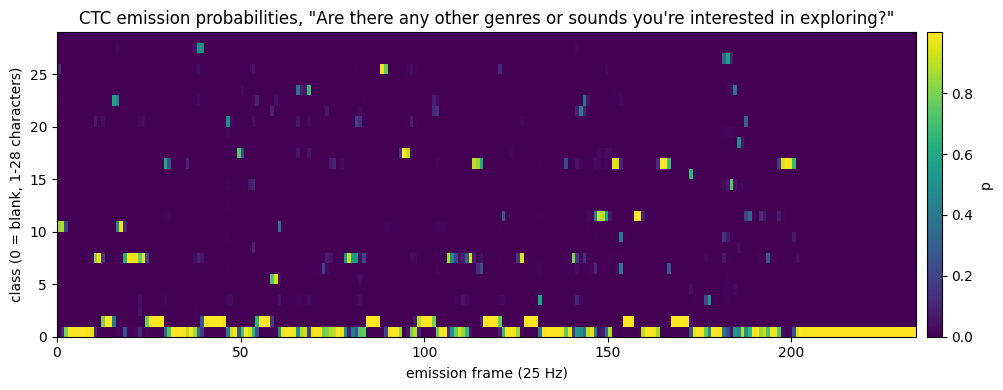

In [8]:
# longest test target
pick = max((test_ds[i] for i in range(len(test_ds))), key=lambda t: len(t.data["target"]))
b = collate([pick])
model.eval()
with torch.no_grad():
    logp, n_valid = model(normalized(b), b.lengths["neural"])
pred = greedy(logp[0], int(n_valid[0]))
ref = pick.data["target"].tolist()
print("sentence :", repr(pick.metadata["text"]))
print("target   :", repr(VOCAB.decode(ref)))
print("decoded  :", repr(VOCAB.decode(pred)))
print(f"CER      : {levenshtein(pred, ref) / len(ref):.3f}")

probs = logp[0, : int(n_valid[0])].exp().numpy()                       # (T', 29)
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(probs.T, aspect="auto", origin="lower", cmap="viridis", extent=[0, probs.shape[0], 0, VOCAB.n_classes])
ax.set(xlabel="emission frame (25 Hz)", ylabel="class (0 = blank, 1-28 characters)", title=f'CTC emission probabilities, "{pick.metadata["text"]}"')
fig.colorbar(im, ax=ax, label="p", pad=0.01)
plt.tight_layout()
plt.show()

## Notes

- **Protocol.** Area 6v only, the competition partition of two days (train blocks against the day's test block), per-block z-scoring from each block's own frames, a length-aware CTC model, final-epoch CER on the test blocks with no selection on them. The Study query drops any timelines flagged `valid=False`. None fall on these two days.
- **The authors' recipe**, for a decoder meant to be compared with the paper: per-block z-scoring, causal Gaussian smoothing (SD 40 ms, delayed 160 ms), a day-specific input layer, a temporal conv with kernel 14 and stride 4 in front of a 5-layer 512-unit GRU trained with noise regularization, ARPAbet phoneme targets and an n-gram language model on top. This notebook keeps the first item and the strided front end, and swaps phonemes for characters because the release has no phoneme labels for these sentences.
- **Splits.** `original_split` is block-based and not prompt-disjoint: the cell above counts the test sentences of these two days that also occur in their train blocks. For prompt-disjoint evaluation group by normalized sentence text, for temporal generalization split by session (see the README, Notes).
- **What would move the number.** More sessions with a day-specific input layer, phoneme targets from a grapheme-to-phoneme model or the authors' `derived/tfRecords`, and a language model for greedy-to-beam decoding.